In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
SCRIPT_DIR = Path.cwd()
DATA_PATH = SCRIPT_DIR / "USSeatBelts.csv"
if not DATA_PATH.exists():
    DATA_PATH = SCRIPT_DIR.parent / "USSeatBelts.csv"
def load_seatbelts():
    if not DATA_PATH.exists():
        raise FileNotFoundError(
            f"Could not find the dataset at {DATA_PATH.resolve()}. "
            "Place USSeatBelts.csv in this folder."
        )
    return pd.read_csv(DATA_PATH)

In [2]:
def show_data(df):
    print("\nSHAPE:", df.shape)
    print("\nCOLUMNS:", list(df.columns))

    print("\nDATA INFORMATION:")
    df.info()

    print("\nFIRST SIX ROWS:\n", df.head(6))
    print("\nLAST SIX ROWS:\n", df.tail(6))
    print("\nSUMMARY STATISTICS:\n", df.describe(include="all").T)
def display_assignments(results, title, output_path):
    print(f"\n{title}")
    print("-" * 45)
    print("Total observations:", len(results))
    print("Number of clusters:", results["Cluster"].nunique())

    print("\nCLUSTER COUNTS:")
    print(results["Cluster"].value_counts().sort_index().to_string())

    print("\nFIRST 20 CLUSTER ASSIGNMENTS:")
    print(results.head(20).to_string(index=False))

    print("\nLAST 10 CLUSTER ASSIGNMENTS:")
    print(results.tail(10).to_string(index=False))

    results.to_csv(output_path, index=False)
    print("\nComplete assignments saved to:")
    print(output_path)

In [3]:
df = load_seatbelts()
show_data(df)
# Check missing values
print("\nMISSING VALUES IN EACH COLUMN:")
print(df.isnull().sum().to_string())
print("\nTOTAL MISSING VALUES:", df.isnull().sum().sum())
# Display distributions of relevant categorical variables
for col in ["state", "speed65", "speed70", "drinkage", "alcohol", "enforce"]:
    if col in df.columns:
        print(f"\nDISTRIBUTION OF {col.upper()}:")
        print(df[col].value_counts(dropna=False).to_string())
# Select numerical features
num = df.select_dtypes(include=np.number).drop(
    columns=["rownames"], errors="ignore"
)
print("\nNUMERICAL FEATURES:")
print(list(num.columns))
# Remove rows with missing numerical values
rows_before = len(num)
num = num.dropna()
rows_dropped = rows_before - len(num)
print("\nROWS BEFORE REMOVING MISSING VALUES:", rows_before)
print("ROWS DROPPED:", rows_dropped)
print("ROWS USED FOR CLUSTERING:", len(num))
if len(num) < 3:
    raise ValueError("At least 3 complete observations are required.")
# Standardize numerical features
scaler = StandardScaler()


SHAPE: (765, 13)

COLUMNS: ['rownames', 'state', 'year', 'miles', 'fatalities', 'seatbelt', 'speed65', 'speed70', 'drinkage', 'alcohol', 'income', 'age', 'enforce']

DATA INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    765 non-null    int64  
 1   state       765 non-null    str    
 2   year        765 non-null    int64  
 3   miles       765 non-null    int64  
 4   fatalities  765 non-null    float64
 5   seatbelt    556 non-null    float64
 6   speed65     765 non-null    str    
 7   speed70     765 non-null    str    
 8   drinkage    765 non-null    str    
 9   alcohol     765 non-null    str    
 10  income      765 non-null    int64  
 11  age         765 non-null    float64
 12  enforce     765 non-null    str    
dtypes: float64(3), int64(4), str(6)
memory usage: 77.8 KB

FIRST SIX ROWS:
    rownames state  year  mile

In [4]:
scaled = scaler.fit_transform(num)
scaled_df = pd.DataFrame(scaled, columns=num.columns, index=num.index)
print("\nSTANDARDIZED DATA (FIRST SIX ROWS):")
print(scaled_df.head(6).to_string())


STANDARDIZED DATA (FIRST SIX ROWS):
        year     miles  fatalities  seatbelt    income       age
7  -0.479119 -0.906311    0.967322 -0.463745  0.339599 -4.093312
8  -0.203067 -0.905408    1.064600  0.771311  0.435312 -3.925470
9   0.072985 -0.909278    1.661524  0.771311  0.565871 -3.659215
10  0.349037 -0.907623    2.059479  0.947748  0.710233 -3.482848
11  0.625089 -0.902635    0.141975  0.947748  0.869981 -3.279718
12  0.901141 -0.903215    0.265201  0.947748  0.995336 -2.986322


In [5]:
# Apply K-Means with K = 2
km2 = KMeans(n_clusters=2, n_init=25, random_state=123)
km2_labels = km2.fit_predict(scaled)
print("\nK-MEANS CLUSTERING (K = 2)")
print("-" * 45)
print("\nCLUSTER CENTERS (STANDARDIZED FEATURES):")
print(pd.DataFrame(
    km2.cluster_centers_, columns=num.columns
).to_string(index=False))
print("\nCLUSTER CENTERS (ORIGINAL UNITS):")
print(pd.DataFrame(
    scaler.inverse_transform(km2.cluster_centers_),
    columns=num.columns
).to_string(index=False))
print("\nCLUSTER COUNTS:")
print(pd.Series(km2_labels).value_counts().sort_index().to_string())
km2_results = pd.DataFrame({
    "Observation": num.index,
    "Cluster": km2_labels
})
display_assignments(
    km2_results,
    "K-MEANS ASSIGNMENTS (K = 2)",
    SCRIPT_DIR / "kmeans_k2_assignments.csv"
)


K-MEANS CLUSTERING (K = 2)
---------------------------------------------

CLUSTER CENTERS (STANDARDIZED FEATURES):
     year     miles  fatalities  seatbelt    income       age
-0.822528 -0.146561    0.670070 -0.712861 -0.796743 -0.393637
 0.672000  0.119739   -0.547443  0.582403  0.650934  0.321599

CLUSTER CENTERS (ORIGINAL UNITS):
       year        miles  fatalities  seatbelt       income       age
1988.756000 39317.240000    0.023136  0.407642 16050.988000 34.907956
1994.169935 51703.669935    0.017018  0.627879 22448.931373 35.936761

CLUSTER COUNTS:
0    250
1    306

K-MEANS ASSIGNMENTS (K = 2)
---------------------------------------------
Total observations: 556
Number of clusters: 2

CLUSTER COUNTS:
Cluster
0    250
1    306

FIRST 20 CLUSTER ASSIGNMENTS:
 Observation  Cluster
           7        0
           8        0
           9        0
          10        0
          11        1
          12        1
          13        1
          14        1
          16        0
   


WCSS SCORES:
---------------------------------------------
K                    WCSS
-------------------------
1               3336.0000
2               2225.3868
3               1897.3121
4               1605.3173
5               1426.5752
6               1288.0018
7               1190.3042
8               1097.9794
9               1025.7764
10               963.0475


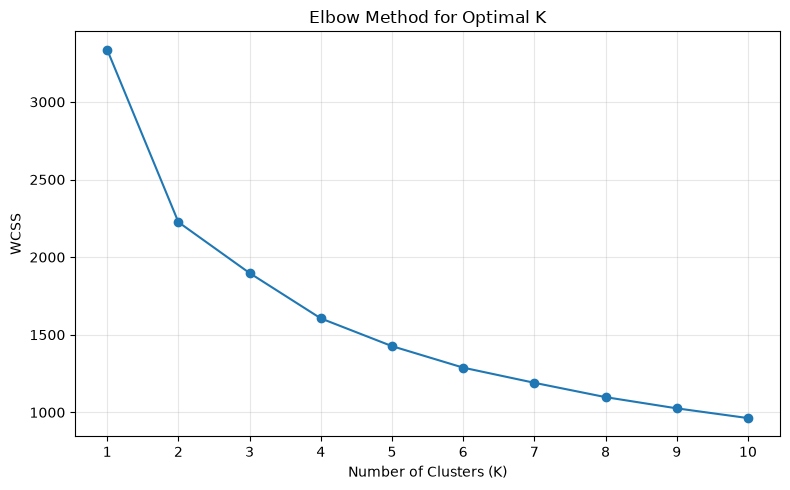

In [6]:
# Calculate WCSS for K = 1 to 10
max_k = min(10, len(scaled))
ks = range(1, max_k + 1)
wcss = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=25, random_state=123)
    model.fit(scaled)
    wcss.append(model.inertia_)
# Print numerical WCSS scores
print("\nWCSS SCORES:")
print("-" * 45)
print(f"{'K':<10}{'WCSS':>15}")
print("-" * 25)
for k, score in zip(ks, wcss):
    print(f"{k:<10}{score:>15.4f}")
# Plot elbow curve
plt.figure(figsize=(8, 5))
plt.plot(list(ks), wcss, marker="o")
plt.xticks(list(ks))
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal K")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# Select K after examining the elbow plot
# Change this value if the elbow suggests another K
optimal_k = min(3, len(scaled))

In [7]:
print(f"\nSELECTED K FOR FINAL K-MEANS MODEL: {optimal_k}")
final_kmeans = KMeans(
    n_clusters=optimal_k,
    n_init=25,
    random_state=123
)
final_labels = final_kmeans.fit_predict(scaled)
print("\nFINAL K-MEANS CLUSTER CENTERS:")
print(pd.DataFrame(
    final_kmeans.cluster_centers_,
    columns=num.columns
).to_string(index=False))
print("\nFINAL K-MEANS CLUSTER COUNTS:")
print(pd.Series(final_labels).value_counts().sort_index().to_string())
final_results = pd.DataFrame({
    "Observation": num.index,
    "Cluster": final_labels
})
display_assignments(
    final_results,
    f"FINAL K-MEANS ASSIGNMENTS (K = {optimal_k})",
    SCRIPT_DIR / "kmeans_final_assignments.csv"
)


SELECTED K FOR FINAL K-MEANS MODEL: 3

FINAL K-MEANS CLUSTER CENTERS:
     year     miles  fatalities  seatbelt    income       age
 0.059840  3.814949   -0.201043  0.776716  0.298945 -1.147176
 0.659596 -0.069147   -0.535606  0.538862  0.645829  0.402399
-0.822163 -0.249566    0.681009 -0.735624 -0.826122 -0.397570

FINAL K-MEANS CLUSTER COUNTS:
0     21
1    296
2    239

FINAL K-MEANS ASSIGNMENTS (K = 3)
---------------------------------------------
Total observations: 556
Number of clusters: 3

CLUSTER COUNTS:
Cluster
0     21
1    296
2    239

FIRST 20 CLUSTER ASSIGNMENTS:
 Observation  Cluster
           7        2
           8        2
           9        2
          10        2
          11        1
          12        1
          13        1
          14        1
          16        2
          17        2
          18        2
          19        2
          20        2
          21        2
          22        2
          23        2
          24        2
          25     


HIERARCHICAL CLUSTERING
---------------------------------------------
Distance metric: Euclidean
Linkage method: Ward
Number of pairwise distances: 154290
First 10 Euclidean distances: [1.2839 1.5974 2.0931 2.1991 2.4588 2.8127 3.2326 4.9309 4.7217 4.6858]


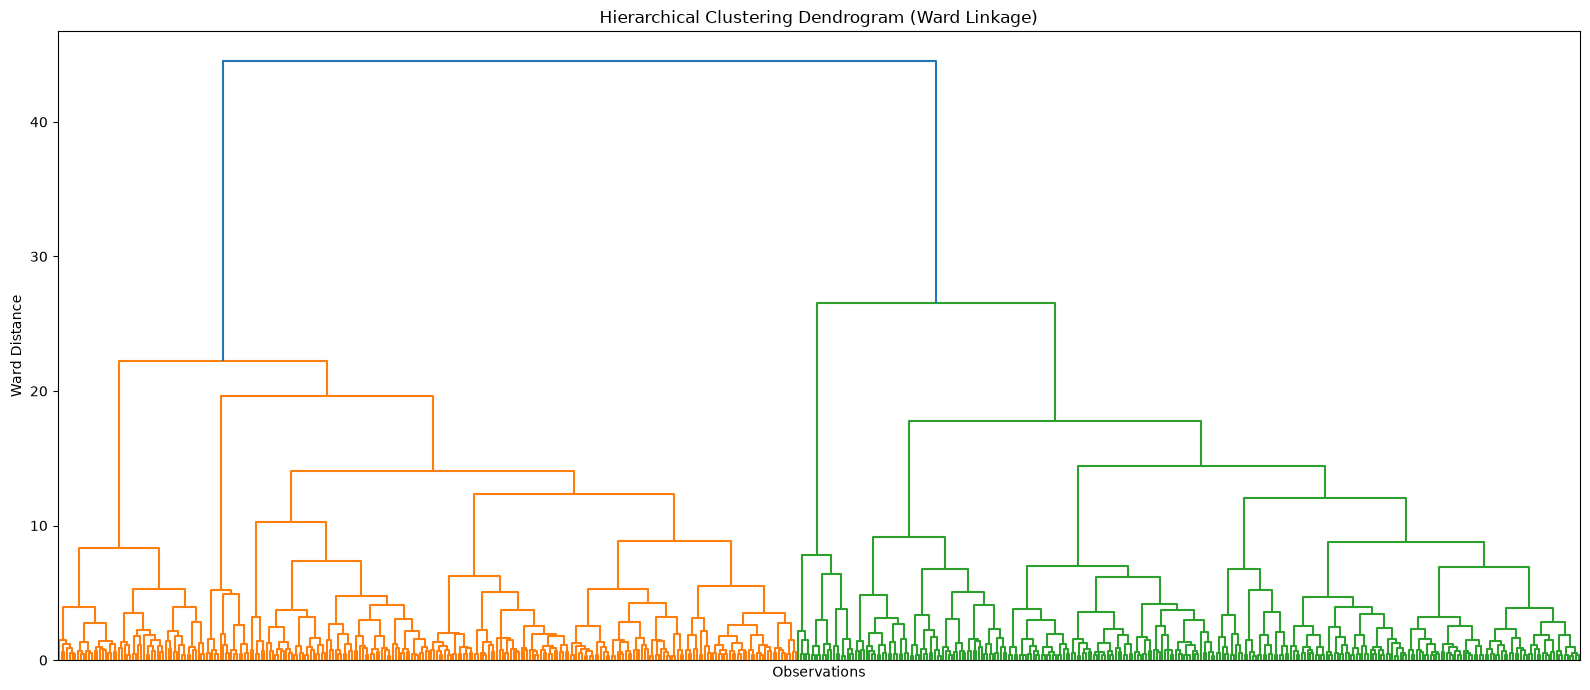


HIERARCHICAL CLUSTER ASSIGNMENTS (3 CLUSTERS)
---------------------------------------------
Total observations: 556
Number of clusters: 3

CLUSTER COUNTS:
Cluster
1    270
2     21
3    265

FIRST 20 CLUSTER ASSIGNMENTS:
 Observation  Cluster
           7        1
           8        1
           9        1
          10        1
          11        1
          12        1
          13        1
          14        1
          16        1
          17        1
          18        1
          19        1
          20        1
          21        1
          22        1
          23        1
          24        3
          25        3
          26        3
          27        3

LAST 10 CLUSTER ASSIGNMENTS:
 Observation  Cluster
         748        3
         749        3
         757        1
         758        1
         759        1
         760        1
         761        3
         762        3
         763        3
         764        3

Complete assignments saved to:
c:\Users\akr

In [8]:
# Calculate Euclidean distances
euclidean_distances = pdist(scaled, metric="euclidean")

print("\nHIERARCHICAL CLUSTERING")
print("-" * 45)
print("Distance metric: Euclidean")
print("Linkage method: Ward")
print("Number of pairwise distances:", len(euclidean_distances))
print("First 10 Euclidean distances:", np.round(euclidean_distances[:10], 4))

# Perform Ward hierarchical clustering using all observations
Z = linkage(scaled, method="ward", metric="euclidean")

# Plot dendrogram
plt.figure(figsize=(16, 7))
dendrogram(Z, no_labels=True)
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Observations")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

# Divide observations into 3 hierarchical clusters
hc_labels = fcluster(Z, t=3, criterion="maxclust")

hc_results = pd.DataFrame({
    "Observation": num.index,
    "Cluster": hc_labels
})

display_assignments(
    hc_results,
    "HIERARCHICAL CLUSTER ASSIGNMENTS (3 CLUSTERS)",
    SCRIPT_DIR / "hierarchical_cluster_assignments.csv"
)

# Cross-check using sklearn AgglomerativeClustering
hc_model = AgglomerativeClustering(n_clusters=3, linkage="ward")
hc_sklearn_labels = hc_model.fit_predict(scaled) + 1

print("\nAGGLOMERATIVE CLUSTERING COUNTS (SKLEARN):")
print(pd.Series(hc_sklearn_labels).value_counts().sort_index().to_string())